# Soluzioni — Lezione 6: Significato e similarità
[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/solutions/06_significato_similarita_clustering_soluzioni.ipynb)

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

STOPWORDS = set()
for riga in (DATI / "stopwords_it.txt").read_text(encoding="utf-8").splitlines():
    if not riga.startswith("#"):
        STOPWORDS.update(riga.split())
STOPWORDS = sorted(STOPWORDS)

def leggi_testo(nome):
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

def frasi(testo, min_parole=5):
    testo = " ".join(testo.split())
    return [f for f in re.split(r"(?<=[.!?;])\s+", testo) if len(f.split()) >= min_parole]

## Esercizio 1 — Un motore di ricerca per la Commedia

In [3]:
dc = pd.read_csv(DATI / "commedia_canti.csv")
terzine = []
for _, canto in dc.iterrows():
    versi = canto["testo"].split("\n")
    for i in range(0, len(versi) - 2, 3):
        terzine.append({"cantica": canto["cantica"], "canto": canto["canto"], "verso": i + 1,
                        "testo": " / ".join(versi[i:i + 3])})
terzine = pd.DataFrame(terzine)
print(len(terzine), "terzine")

motore_dc = TfidfVectorizer(sublinear_tf=True)
T = motore_dc.fit_transform(terzine["testo"])

def cerca_terzine(domanda, n=5):
    punteggi = cosine_similarity(motore_dc.transform([domanda]), T)[0]
    risultati = terzine.iloc[np.argsort(punteggi)[::-1][:n]].copy()
    risultati["similarità"] = np.sort(punteggi)[::-1][:n].round(2)
    return risultati

for domanda in ["la luce della gioia eterna", "amor che move il sole e l'altre stelle"]:
    print("\n>>>", domanda)
    for _, r in cerca_terzine(domanda).iterrows():
        print(f"{r['similarità']}  {r['cantica']} {r['canto']}, v. {r['verso']}: {r['testo'][:110]}")

4720 terzine

>>> la luce della gioia eterna
0.4  Paradiso XXIV, v. 88: Appresso uscì de la luce profonda / che lì splendeva: «Questa cara gioia / sopra la quale ogne virtù si fonda,
0.26  Paradiso XIV, v. 22: così, a l’orazion pronta e divota, / li santi cerchi mostrar nova gioia / nel torneare e ne la mira nota.
0.26  Paradiso IX, v. 37: Di questa luculenta e cara gioia / del nostro cielo che più m’è propinqua, / grande fama rimase; e pria che mo
0.25  Inferno I, v. 76: Ma tu perché ritorni a tanta noia? / perché non sali il dilettoso monte / ch’è principio e cagion di tutta gio
0.23  Paradiso XV, v. 85: Ben supplico io a te, vivo topazio / che questa gioia prezïosa ingemmi, / perché mi facci del tuo nome sazio».

>>> amor che move il sole e l'altre stelle
0.62  Paradiso XXXIII, v. 145: l’amor che move il sole e l’altre stelle. / - - - - - - - - - - - - - - - - - - - - - - - / TAVOLA DEI CARATTE
0.26  Paradiso XVIII, v. 97: E vidi scendere altre luci dove / era il colmo de l’emme, e 

**Commento.** I risultati per la *gioia eterna* cadono quasi tutti nel **Paradiso**: il lessico della luce e della letizia è
caratteristico della terza cantica. Notate che le terzine sono approssimate (il primo verso di ogni canto è contato da 1, e
l'ultimo verso isolato viene escluso).

## Esercizio 2 — L'albero di Pinocchio

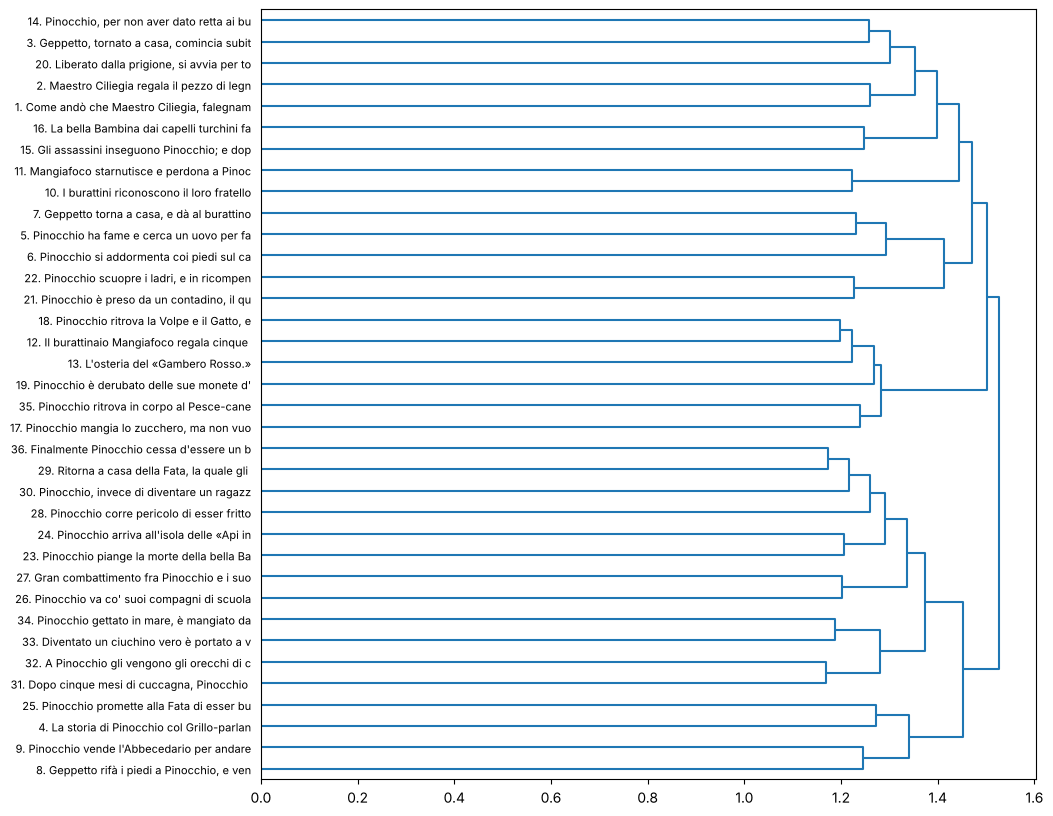


gruppo 1: capitoli [4, 8, 9, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36]

gruppo 2: capitoli [12, 13, 17, 18, 19, 35]

gruppo 3: capitoli [5, 6, 7, 21, 22]

gruppo 4: capitoli [1, 2, 3, 10, 11, 14, 15, 16, 20]


In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
pin = pd.read_csv(DATI / "pinocchio_capitoli.csv")
Xp = TfidfVectorizer(stop_words=STOPWORDS, min_df=2, sublinear_tf=True).fit_transform(pin["testo"])
Zp = linkage(Xp.toarray(), method="ward")
etichette = [f"{c}. {t[:40]}" for c, t in zip(pin["capitolo"], pin["titolo"])]
plt.figure(figsize=(10, 10))
dendrogram(Zp, labels=etichette, orientation="right", leaf_font_size=8)
plt.show()

pin["gruppo"] = fcluster(Zp, t=4, criterion="maxclust")
for g, gr in pin.groupby("gruppo"):
    print(f"\ngruppo {g}: capitoli {gr['capitolo'].tolist()}")

**Commento.** I capitoli tendono a stare insieme perché **condividono personaggi e luoghi**: per esempio un gruppo raccoglie gli
episodi delle **monete d'oro** e del **Gatto e la Volpe** (capitoli 12–13 e 18–19), con qualche "intruso" (17, 35) che condivide
parte del lessico; un altro raccoglie l'inizio, con Geppetto e il pezzo di legno. Il clustering trova **episodi**, non temi astratti: la somiglianza lessicale segue
i nomi propri e gli oggetti di scena. Per trovare "fasi morali" della storia servirebbe un'altra rappresentazione (o una lettura).

## Esercizio 3 — Ingannare la macchina

In [5]:
coppie = [
    # similarità alta, senso diverso
    ("Era felice di partire.", "Era felice di non partire."),
    ("La felicità non è un sogno.", "La felicità è un sogno."),
    ("Lucia era contenta di Renzo.", "Renzo era contento di Lucia."),
    # similarità bassa, senso simile
    ("Era al settimo cielo.", "Non stava più nella pelle dalla contentezza."),
    ("Che gioia!", "Evviva, finalmente!"),
    ("Sorrise beato.", "Aveva un'aria lieta."),
]
tutte = [f for c in coppie for f in c]
cv = CountVectorizer(token_pattern=r"(?u)\b\w+\b").fit(tutte)
for a, b in coppie:
    print(f"{cosine_similarity(cv.transform([a]), cv.transform([b]))[0, 0]:.2f}   {a!r} ↔ {b!r}")

0.89   'Era felice di partire.' ↔ 'Era felice di non partire.'
0.91   'La felicità non è un sogno.' ↔ 'La felicità è un sogno.'
0.80   'Lucia era contenta di Renzo.' ↔ 'Renzo era contento di Lucia.'
0.00   'Era al settimo cielo.' ↔ 'Non stava più nella pelle dalla contentezza.'
0.00   'Che gioia!' ↔ 'Evviva, finalmente!'
0.00   'Sorrise beato.' ↔ "Aveva un'aria lieta."


**Commento.** Le prime tre coppie hanno similarità altissima ma senso opposto o diverso (negazione, ruoli scambiati).
Le ultime tre hanno similarità zero o quasi, ma dicono cose vicine con **modi di dire**, **sinonimi** o **forme diverse
della stessa parola** (*contenta/contento* sono due parole diverse per il vettorizzatore!).